# Module 5 — Equity Markets: run the whole module

**How to use:**
- **Run all** to run the full module in order, or run a single cell to run one step.
- Each cell runs one task notebook in full and shows all its tables and charts here.
- Every task notebook also runs on its own: open it from `notebooks/` and run all.

**Order matters:** Task 2 reads the files Task 1 saves in `outputs/task1/`.

| Step | Notebook | Status |
| --- | --- | --- |
| 0. Data check | `helpers/m05_data.py` | Built |
| 1. Task 1 — Predict future returns by various models | `notebooks/m05_task1_returns.ipynb` | Built |
| 2. Task 2 — Stock ranking and portfolio | `notebooks/m05_task2_ranking.ipynb` | Built |
| Final. Output workbook | `helpers/m05_final_output.py` → `outputs/FINAL_M5_module_output.xlsx` | Built |


## Setup
Moves into the module folder so the paths below work, both locally and in Google Colab.
- **Colab:** upload the whole unzipped project folder (any name) to Google Drive; the cell below finds it. Then run all cells.

In [1]:
import os
import sys
from pathlib import Path

# ---- Find the project folder: any folder name works, on your computer or in Google Colab ----
# The project folder is the one holding run_novafin.ipynb and data/.
IN_COLAB = "google.colab" in sys.modules
is_project = lambda p: (p / "run_novafin.ipynb").exists() and (p / "data").is_dir()
places = [p for p in [Path.cwd(), *Path.cwd().parents] if is_project(p)]
if IN_COLAB and not places:                                 # Colab starts outside the project: look in /content, then in Google Drive
    for base in [Path("/content"), Path("/content/drive/MyDrive")]:
        if "drive" in base.parts:
            from google.colab import drive
            drive.mount("/content/drive")                   # asks for access to your Google Drive
        for depth in ["", "*/", "*/*/", "*/*/*/"]:
            places += [f.parent for f in sorted(base.glob(depth + "run_novafin.ipynb")) if is_project(f.parent)]
        if places:
            break
if not places:
    raise FileNotFoundError("Project folder not found: unzip the whole project and keep run_novafin.ipynb, data/ and the module folders together (see HOW_TO_RUN.md).")
PROJECT_ROOT = places[0]
os.chdir(PROJECT_ROOT / "module_05_equity_markets")                  # the paths below start from the module folder
print("Working folder:", Path.cwd().name)

Working folder: module_05_equity_markets


## 0. Data check
Is `nova_market_data.csv` complete and clean? Prints rows, missing values, duplicates, stocks, dates, and the number of month-end rebalance dates.

In [2]:
%run helpers/m05_data.py

rows: 21855
missing_values: 0
duplicate_rows: 0
tickers: 15
rows_per_ticker: [1457]
date_range: ('2021-01-29', '2026-08-31')
sectors: ['Auto', 'Banking', 'Consumer', 'Energy', 'Healthcare', 'IT', 'Industrials', 'Telecom']
Return_is_same_day_close_to_close: True
month_end_rebalance_dates: 68


## 1. Task 1 — Predict future returns by various models
Runs `notebooks/m05_task1_returns.ipynb` (about 50 minutes, mostly the shuffled-returns test).
- what the data and its macro columns really contain;
- 22 inputs built and tested against the next day, week and month; combinations of conditions;
- five ways of predicting, walk-forward over 43 test months; each model against 100 runs on shuffled returns;
- what an IC is worth in ₹;
- saves `outputs/task1/FINAL_M5_T1_return_predictions.csv` for Task 2.

nbformat\__init__.py:96: MissingIDFieldWarning: Cell is missing an id field, this will become a hard error in future nbformat versions. You may want to use `normalize()` on your notebooks before validations (available since nbformat 5.1.4). Previous versions of nbformat are fixing this issue transparently, and will stop doing so in the future.
  validate(nb)


Outputs go to: module_05_equity_markets/outputs/task1
rows: 21855
missing_values: 0
duplicate_rows: 0
tickers: 15
rows_per_ticker: [1457]
date_range: ('2021-01-29', '2026-08-31')
sectors: ['Auto', 'Banking', 'Consumer', 'Energy', 'Healthcare', 'IT', 'Industrials', 'Telecom']
Return_is_same_day_close_to_close: True
month_end_rebalance_dates: 68

Market_Return vs the 15 stocks' average return, same day: correlation -0.016 (a real index: about +0.6 to +0.9)
Average correlation between two stocks' daily returns: +0.004 (real large-caps: about 0.3 to 0.5)


,Column,Different values on the same date (max),Correlation with the day before (average over stocks),Range
0,Market_Return,15,-0.003,-0.05 to 0.05
1,GDP_Growth,15,0.009,3.79 to 9.52
2,Interest_Rate,15,-0.004,3.63 to 9.30
3,VIX,15,-0.008,8.00 to 36.60


Rows: 1,005 = 67 months × 15 stocks (68 month-ends − 1, because the last month-end has no month after it)
Up months 54.8%, down 45.2%  → nearly balanced, no balancing needed
Average 1.17% a month; typical swing (sd) ±8.64%; range -22.1% to 31.6%
Beyond 3 sd: 2 of 1,005 (a bell curve gives about 2.7)
Lopsidedness (skew, 0 = symmetric) 0.14; fat tails (excess kurtosis, 0 = bell curve) 0.03
Spread between stocks in the same month (average sd) 8.52%; spread of the 15-stock average from month to month 2.16%


Tests: 22 inputs × 3 horizons = 66; line = 0.05 ÷ 66 = 0.0008
Passing: 0 of 22 inputs;  smallest p anywhere 0.019


,Input,Group,IC next day,p next day,IC next week,p next week,IC next month,p next month,Smallest p,Passes the line
0,Past_1D,Price / trading,0.011,0.494,-0.000,0.988,-0.026,0.423,0.423,No
1,Past_5D,Price / trading,0.020,0.187,-0.005,0.782,-0.030,0.410,0.187,No
2,Past_20D,Price / trading,0.016,0.290,0.010,0.555,-0.002,0.937,0.290,No
3,Past_60D,Price / trading,0.023,0.158,-0.011,0.516,-0.019,0.597,0.158,No
4,Past_120D,Price / trading,0.013,0.459,-0.024,0.141,-0.039,0.266,0.141,No
5,Past_250D,Price / trading,0.022,0.274,-0.024,0.175,-0.053,0.146,0.146,No
6,Volatility_60D,Price / trading,0.004,0.799,0.011,0.500,0.038,0.260,0.260,No
7,Dist_MA50,Price / trading,0.016,0.298,-0.007,0.685,-0.041,0.250,0.250,No
8,RSI_14,Price / trading,0.001,0.958,0.005,0.753,0.000,0.993,0.753,No
9,Volume_z,Price / trading,-0.004,0.799,-0.014,0.398,0.014,0.614,0.398,No


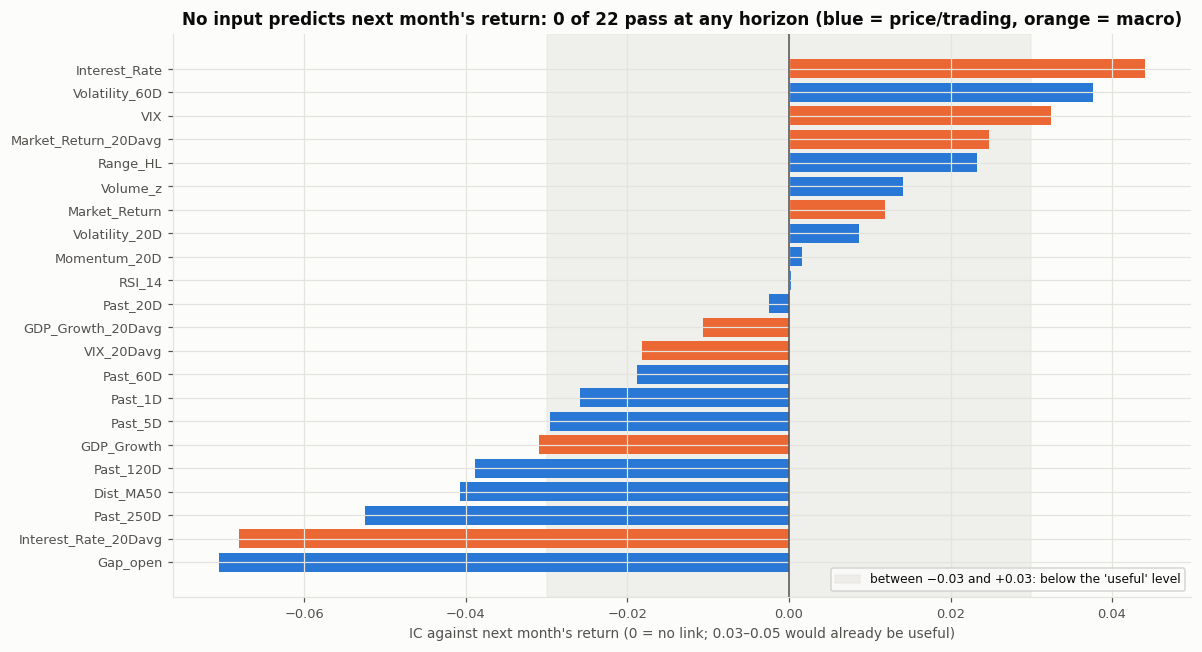

Strongest pairs:
  Past_20D ~ Momentum_20D: +1.00
  Past_20D ~ Dist_MA50: +0.87
  Dist_MA50 ~ Momentum_20D: +0.87
  RSI_14 ~ Momentum_20D: +0.83
  Past_20D ~ RSI_14: +0.83
  Dist_MA50 ~ RSI_14: +0.79
Largest correlation among the given columns: 0.072


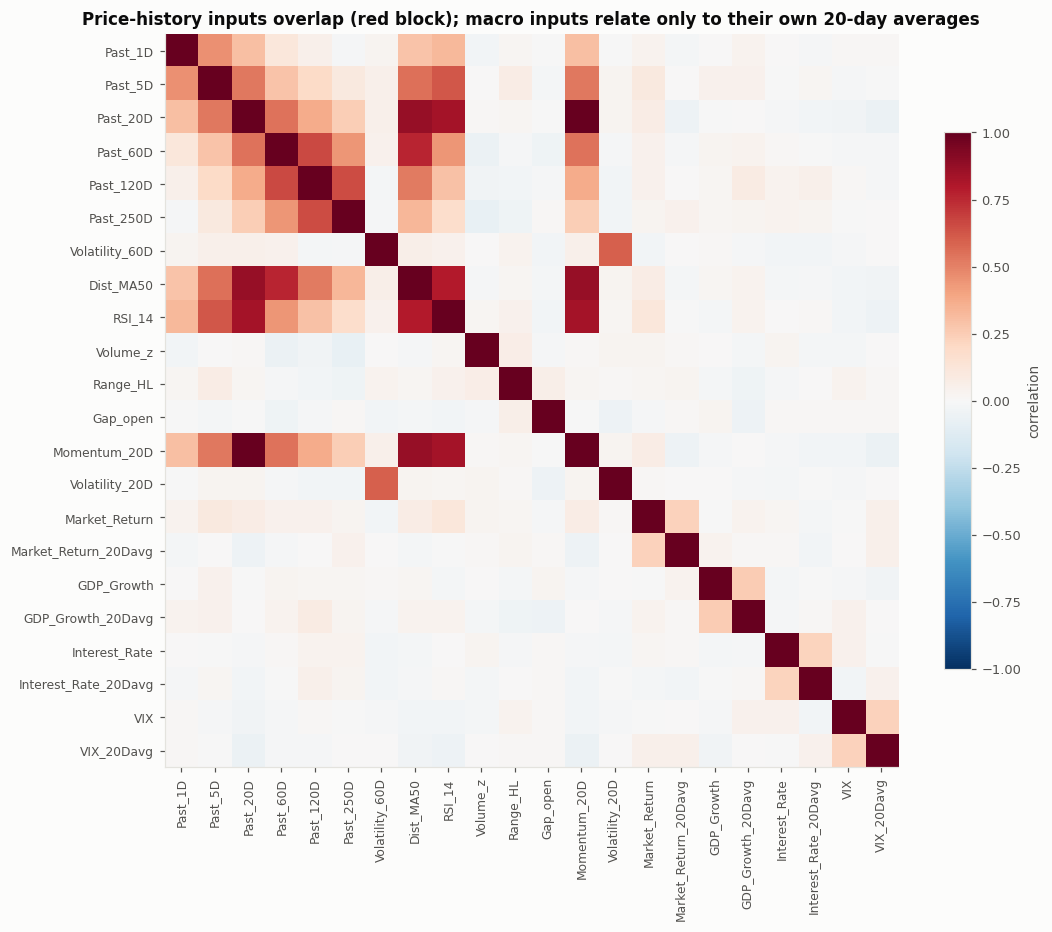

Average monthly return by sector: Telecom 0.11%, Industrials 0.30%, Auto 0.97%, Banking 1.18%, Consumer 1.19%, Healthcare 1.44%, IT 1.61%, Energy 2.00%
Do sectors differ?        p = 0.96
Do calendar months differ? p = 0.73
High vs low VIX months: 0.91% vs 1.42%, p = 0.40


Rows 825 (months where all 22 inputs exist); conditions 44; pairs tested 946
Best pair: Past_250D bottom third AND GDP_Growth bottom third: 86 stock-months, beat the month's average by 2.73% a month
Tested on its own: p = 0.012
Best pair on shuffled returns: average 2.71%, 95th percentile 3.26% → p = 0.48
Inputs: 13 + 8 sector columns = 21


,Input,Meaning
0,Past_1D,return over the last day
1,Past_5D,return over the last week (5 trading days)
2,Past_60D,return over the last 3 months (60 trading days)
3,Past_120D,return over the last 6 months (120 trading days)
4,Past_250D,return over the last year (250 trading days)
5,Volatility_60D,how much daily returns swung over 60 days
6,Dist_MA50,how far the price is above (+) or below (−) it...
7,RSI_14,relative strength index: 0–100 gauge of recent...
8,Volume_z,"today's trading volume vs its 60-day normal, i..."
9,Range_HL,"today's high minus low, as a share of the clos..."


Test months: 43 (Jan 2023 – Jul 2026)


Walk-forward done in 29 s; 645 test predictions per model


'Always up' hit rate = share of up stock-months in the test period = 55.0%


,Model,IC,IC p (t-test),Months IC > 0,RMSE,MAE,Hit rate,Hit rate of 'always up'
0,Predict zero,—,—,—,8.67%,6.89%,—,55.0%
1,Past average,-0.002,0.96,42%,8.65%,6.91%,52.7%,55.0%
2,Linear regression,+0.005,0.92,56%,8.74%,6.91%,52.9%,55.0%
3,Ridge regression,+0.004,0.93,53%,8.73%,6.91%,54.0%,55.0%
4,Random forest,-0.049,0.35,37%,8.77%,6.92%,53.3%,55.0%
5,LightGBM,-0.015,0.70,49%,8.94%,7.08%,52.6%,55.0%
6,"Ridge regression, all 22 inputs",-0.007,0.86,49%,8.77%,6.94%,54.9%,55.0%
7,"LightGBM, all 22 inputs",-0.003,0.93,53%,8.92%,7.05%,52.9%,55.0%


one run takes 26 s; 100 runs ≈ 43 min


Shuffled test done in 56 min
Line: 0.05 ÷ 4 = 0.0125


,Model,IC,Luck: 95% range low,Luck: 95% range high,p (shuffled),Beats luck?
0,Linear regression,+0.005,-0.076,+0.079,0.53,No
1,Ridge regression,+0.004,-0.075,+0.077,0.53,No
2,Random forest,-0.049,-0.074,+0.080,0.93,No
3,LightGBM,-0.015,-0.083,+0.076,0.64,No


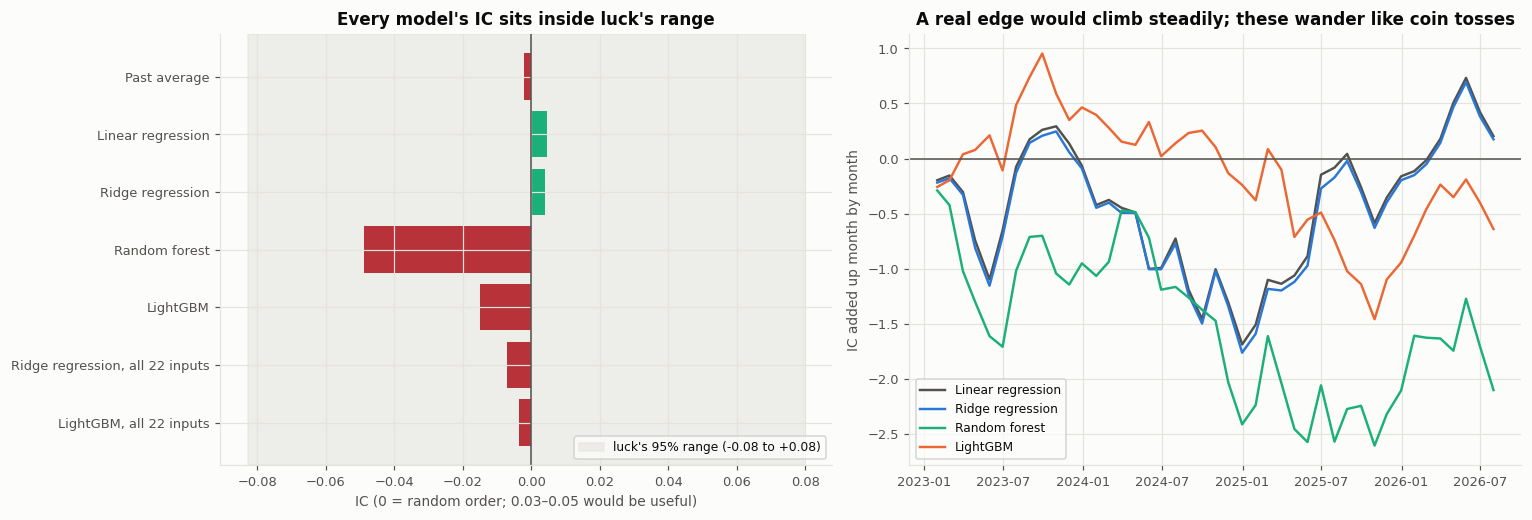

Verdict: are returns predictable from this data? No: no model beats luck
Average score of the best 5 of 15 = 1.03 typical gaps above average;  spread between stocks = 8.52%


,IC,Meaning,Extra a month,Extra a year,₹ crore a year on ₹100 crore
0,+0.030,useful in real markets (low end),+0.26%,+3.2%,₹+3.2
1,+0.050,useful (high end),+0.44%,+5.3%,₹+5.3
2,+0.080,smallest IC this test could detect (M5-04),+0.70%,+8.4%,₹+8.4
3,+0.005,Linear regression (this data),+0.04%,+0.5%,₹+0.5
4,+0.004,Ridge regression (this data),+0.04%,+0.4%,₹+0.4
5,-0.049,Random forest (this data),-0.43%,-5.2%,₹-5.2
6,-0.015,LightGBM (this data),-0.13%,-1.6%,₹-1.6


Saved to module_05_equity_markets/outputs/task1
['01_input_tests.png', '02_input_correlations.png', '03_models_vs_luck.png', 'FINAL_M5_T1_return_predictions.csv', 'evidence_table.csv', 'key_numbers.json', 'model_tests.csv']


In [3]:
%run notebooks/m05_task1_returns.ipynb

## 2. Task 2 — Stock ranking and portfolio
Runs `notebooks/m05_task2_ranking.ipynb` (under a minute; reads Task 1's predictions):
- on every rebalance date, ranks the 15 stocks by each model's prediction, selects the top 5 and holds them equally;
- compares each portfolio with holding all 15 stocks and with 1,000 random picks; checks top 3 and top 7;
- risk of 5 stocks vs 15; what it means in ₹;
- every strategy's top 5 for September 2026 (the latest rebalance date); checks with quarterly rebalancing and other weightings;
- saves `outputs/task2/FINAL_M5_T2_stock_selections.csv` (rank, selected, reason per stock and month) and the portfolio returns.

Reads from: module_05_equity_markets/outputs/task1
Outputs go to: module_05_equity_markets/outputs/task2
Line for 'beats the benchmark': 0.05 ÷ 5 strategies = 0.010
645 rows = 43 rebalance dates × 15 stocks
Rebalance dates: 31 Jan 2023 to 31 Jul 2026; last portfolio held until 31 Aug 2026
Period invested: 43 months = 3.58 years
Rankers used: Past average, Linear regression, Ridge regression, Random forest, LightGBM
Task 1's verdict carried in the file: No: no model beats luck


,Date,Ticker,Sector,Next_Month_Return,Pred: Predict zero,Pred: Past average,Pred: Linear regression,Pred: Ridge regression,Pred: Random forest,Pred: LightGBM,"Pred: Ridge regression, all 22 inputs","Pred: LightGBM, all 22 inputs",Returns predictable,Held until
0,2023-01-31,AXISBANK,Banking,0.039091,0.0,0.007202,-0.037498,-0.033807,-0.016224,-0.014545,-0.019219,0.015620,No: no model beats luck,2023-02-28
1,2023-01-31,BHARTIARTL,Telecom,-0.141212,0.0,0.008297,-0.024830,-0.024183,-0.014816,-0.005037,-0.037884,0.005863,No: no model beats luck,2023-02-28
2,2023-01-31,HDFCBANK,Banking,0.056642,0.0,0.008702,0.001615,0.001834,0.000671,-0.006618,0.005028,0.031189,No: no model beats luck,2023-02-28


Example: ridge regression on 31 Jan 2023; top 5 selected at 20% each


Rank,Ticker,Sector,Predicted return,Selected,Weight,Next_Month_Return
1,HINDUNILVR,Consumer,+5.96%,Yes,20%,-13.36%
2,SBIN,Banking,+4.77%,Yes,20%,-7.52%
3,ITC,Consumer,+3.36%,Yes,20%,-8.59%
4,KOTAKBANK,Banking,+2.25%,Yes,20%,+6.17%
5,RELIANCE,Energy,+1.73%,Yes,20%,-11.36%
6,SUNPHARMA,Healthcare,+1.58%,No,0%,-2.64%
7,LT,Industrials,+0.73%,No,0%,-11.41%
8,TITAN,Consumer,+0.28%,No,0%,+12.14%
9,HDFCBANK,Banking,+0.18%,No,0%,+5.66%
10,INFY,IT,-0.34%,No,0%,-2.25%



Share of the 43 months each stock was selected (even spread = 33%):


Ticker,AXISBANK,BHARTIARTL,HDFCBANK,HINDUNILVR,ICICIBANK,INFY,ITC,KOTAKBANK,LT,MARUTI,RELIANCE,SBIN,SUNPHARMA,TCS,TITAN
Strategy,,,,,,,,,,,,,,,
Past average,23%,0%,2%,33%,100%,98%,28%,0%,19%,7%,95%,0%,35%,0%,60%
Linear regression,19%,19%,28%,37%,28%,26%,42%,40%,35%,9%,72%,33%,44%,40%,30%
Ridge regression,21%,16%,30%,37%,28%,26%,42%,37%,35%,9%,72%,33%,40%,42%,33%
Random forest,33%,44%,44%,33%,33%,14%,33%,30%,37%,28%,37%,33%,47%,26%,30%
LightGBM,30%,40%,40%,30%,26%,33%,30%,40%,47%,30%,26%,23%,49%,26%,33%


... (2 outputs left out)

Top 5, equal weight, before trading costs; benchmark = all 15 equal weight (15.8% a year)

Stocks held,Strategy,Annual return,Volatility,Return per unit of risk,Maximum drawdown,Growth of ₹1,Excess a year,p (excess),Months beating the benchmark,Turnover a month,Beats the benchmark?
5,Past average,18.9%,11.2%,1.69,-6.5%,₹1.86,+3.1%,0.60,23,10%,No
5,Linear regression,14.4%,13.0%,1.11,-14.1%,₹1.62,-1.4%,0.92,20,49%,No
5,Ridge regression,15.2%,13.0%,1.17,-11.9%,₹1.66,-0.5%,0.98,20,48%,No
5,Random forest,8.3%,13.2%,0.63,-21.2%,₹1.33,-7.4%,0.40,17,58%,No
5,LightGBM,19.1%,10.9%,1.75,-5.4%,₹1.87,+3.4%,0.57,24,68%,No
15,"All 15, equal weight",15.8%,6.7%,2.34,-3.6%,₹1.69,—,—,—,—,—


Random top 5 (1,000 runs): luck's 95% range of annual return 3.6% to 29.3%; average 15.4% (≈ the benchmark's 15.8%, as it should be)


Strategy,Annual return,Excess a year,p (excess),Share of random picks doing at least as well
Past average,18.9%,+3.1%,0.60,28%
Linear regression,14.4%,-1.4%,0.92,53%
Ridge regression,15.2%,-0.5%,0.98,47%
Random forest,8.3%,-7.4%,0.40,87%
LightGBM,19.1%,+3.4%,0.57,27%
"All 15, equal weight",15.8%,—,—,—


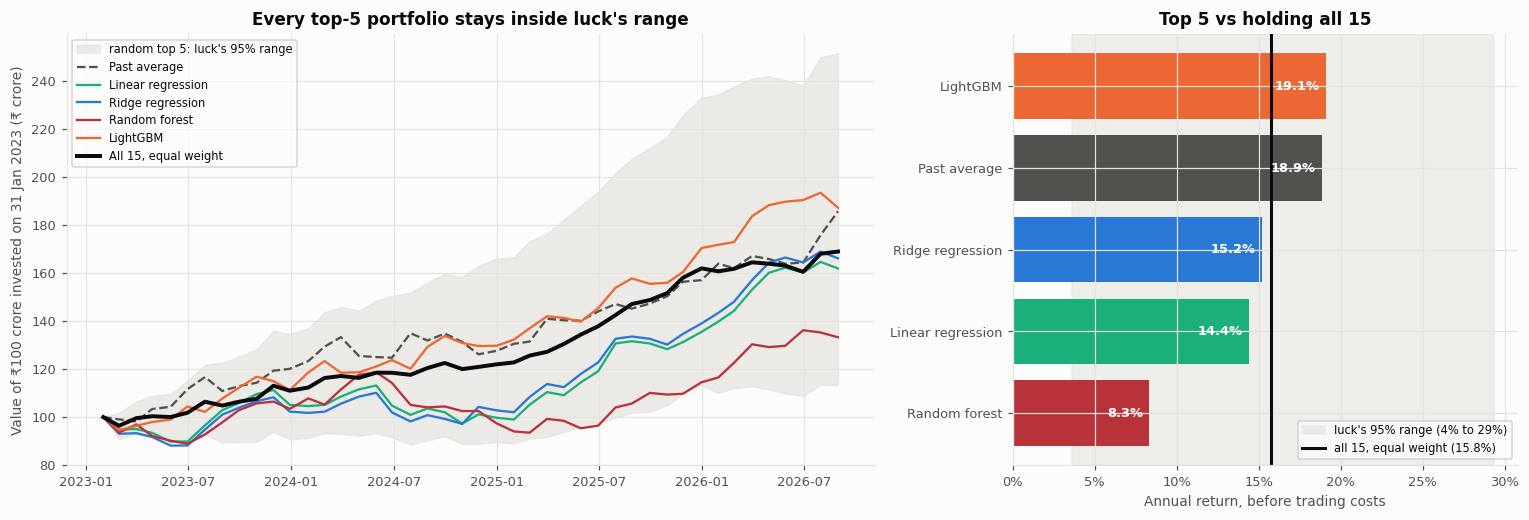

Annual return (p for the excess over all 15), before trading costs


,Top 3,Top 5,Top 7
Strategy,,,
Past average,25.6% (p 0.31),18.9% (p 0.60),12.6% (p 0.53)
Linear regression,9.5% (p 0.54),14.4% (p 0.92),19.8% (p 0.43)
Ridge regression,9.1% (p 0.50),15.2% (p 0.98),20.3% (p 0.38)
Random forest,5.8% (p 0.35),8.3% (p 0.40),9.8% (p 0.35)
LightGBM,19.9% (p 0.60),19.1% (p 0.57),11.7% (p 0.46)
"All 15, equal weight",15.8%,15.8%,15.8%
Luck's 95% range (random picks),-2.6% to 33.7%,3.6% to 29.3%,5.7% to 25.6%


Best strategy at each size: top 3: Past average, top 5: LightGBM, top 7: Ridge regression
Smallest p anywhere: 0.31 (line 0.010)
Average single stock: volatility 29.7% a year
All 15 equal weight: 6.7%;  top-5 strategies: 10.9% to 13.2%  → about 1.8 times the risk of holding all 15


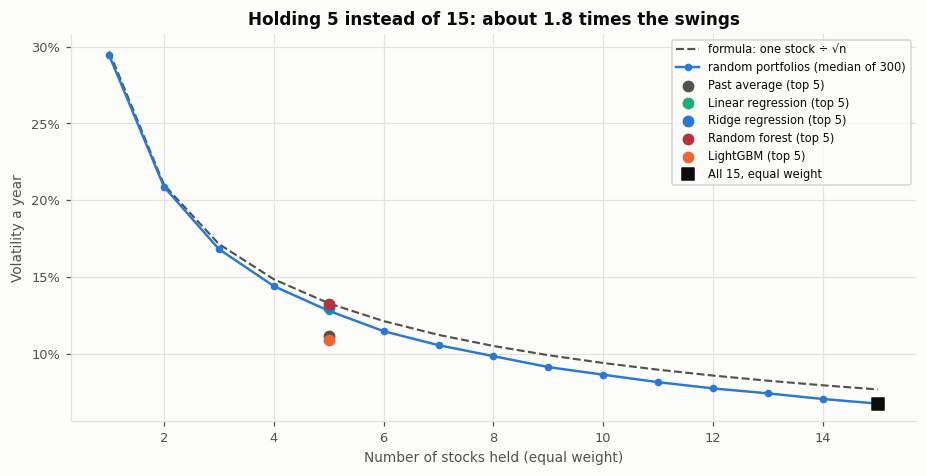

Strategy,Annual return,Excess a year,p (excess),Value on 31 Aug 2026 (₹ crore),Gain vs all 15 (₹ crore),Gap a year (₹ crore),Turnover a month,"Trades a year (sales + purchases, share of the portfolio)"
Past average,18.9%,+3.1%,0.60,₹185.7,₹+16.8,₹+3.1,10%,229%
Linear regression,14.4%,-1.4%,0.92,₹161.9,₹-7.0,₹-1.4,49%,1166%
Ridge regression,15.2%,-0.5%,0.98,₹166.1,₹-2.8,₹-0.5,48%,1143%
Random forest,8.3%,-7.4%,0.40,₹133.2,₹-35.7,₹-7.4,58%,1383%
LightGBM,19.1%,+3.4%,0.57,₹187.2,₹+18.2,₹+3.4,68%,1634%
"All 15, equal weight",15.8%,—,—,₹169.0,₹+0.0,—,—,—


Luck's 95% range for a random top 5, in ₹: ₹113 to ₹251 crore (benchmark ₹169 crore)


Training: 67 months × 15 stocks = 1,005 rows; predicting for 31 Aug 2026 (held to 30 Sep 2026)


Top 5 for September 2026 (predicted next-month return in brackets), 20% each:


Strategy,Past average,Linear regression,Ridge regression,Random forest,LightGBM
Rank,,,,,
1,ICICIBANK (+3.0%),LT (+3.5%),LT (+3.5%),LT (+3.9%),LT (+5.6%)
2,INFY (+2.5%),HDFCBANK (+1.9%),HDFCBANK (+2.0%),BHARTIARTL (+2.5%),SBIN (+3.7%)
3,RELIANCE (+2.0%),ITC (+1.7%),ITC (+1.7%),ITC (+2.4%),ITC (+3.1%)
4,HINDUNILVR (+1.8%),TITAN (+1.6%),TITAN (+1.6%),SBIN (+1.9%),TCS (+2.9%)
5,SUNPHARMA (+1.4%),AXISBANK (+1.1%),AXISBANK (+1.2%),HDFCBANK (+1.9%),ICICIBANK (+2.2%)



How many of the 5 strategies pick each stock: ITC 4, LT 4, HDFCBANK 3, AXISBANK 2, ICICIBANK 2, SBIN 2, TITAN 2, BHARTIARTL 1, HINDUNILVR 1, INFY 1, RELIANCE 1, SUNPHARMA 1, TCS 1
Average stocks shared by two ML models: September 2026 3.0; 43 test months 2.9; random lists 1.7


... (5 outputs left out)

Weighting,Equal (20% each),By rank (33/27/20/13/7%),By predicted return
Strategy,,,
Past average,18.9%,25.7%,29.5%
Linear regression,14.4%,10.2%,7.7%
Ridge regression,15.2%,11.8%,8.6%
Random forest,8.3%,7.4%,7.8%
LightGBM,19.1%,16.5%,12.3%


Volatility, by predicted return: Past average 17.6%, Linear regression 15.0%, Ridge regression 15.0%, Random forest 15.0%, LightGBM 15.3%


Spread of the 15 yearly returns (sd): 15.5%; luck's 95% range 10.4% to 23.5%
Did winners stay winners? Rank correlation (+1 = same order, 0 = unrelated): first half vs second half -0.08 (p 0.77); 2021–22 vs test period +0.45 (p 0.10; 15 stocks, so p must be below 0.05 to count)
Yearly swing ranges only 27.9% to 30.6%: the stocks are equally risky


Rank (best = 1),Ticker,Sector,Yearly return,Yearly swing,Worst fall,First half (yearly),Second half (yearly),Months in top 5: Ridge regression,Forecast-tracking (ridge),September 2026 picks (of 5 strategies)
1,ICICIBANK,Banking,+45.0%,29.3%,-24.8%,+77.5%,+18.5%,12,-0.07,2
2,INFY,IT,+37.4%,28.7%,-18.5%,+43.0%,+32.0%,11,-0.01,1
3,HINDUNILVR,Consumer,+28.7%,30.6%,-21.9%,+11.3%,+48.7%,16,-0.14,1
4,RELIANCE,Energy,+25.8%,29.9%,-32.6%,+19.7%,+32.3%,31,+0.03,1
5,KOTAKBANK,Banking,+17.9%,30.3%,-47.2%,-7.5%,+50.4%,16,+0.03,0
6,AXISBANK,Banking,+17.6%,29.0%,-43.1%,+0.0%,+38.2%,9,-0.11,2
7,SUNPHARMA,Healthcare,+11.3%,28.9%,-38.8%,-5.9%,+31.7%,17,+0.15,1
8,HDFCBANK,Banking,+4.7%,28.7%,-30.5%,+17.4%,-6.6%,13,+0.09,3
9,TCS,IT,+2.8%,28.7%,-37.1%,-16.2%,+26.0%,18,-0.11,1
10,MARUTI,Auto,+2.5%,28.6%,-48.5%,-18.8%,+29.3%,4,+0.03,0


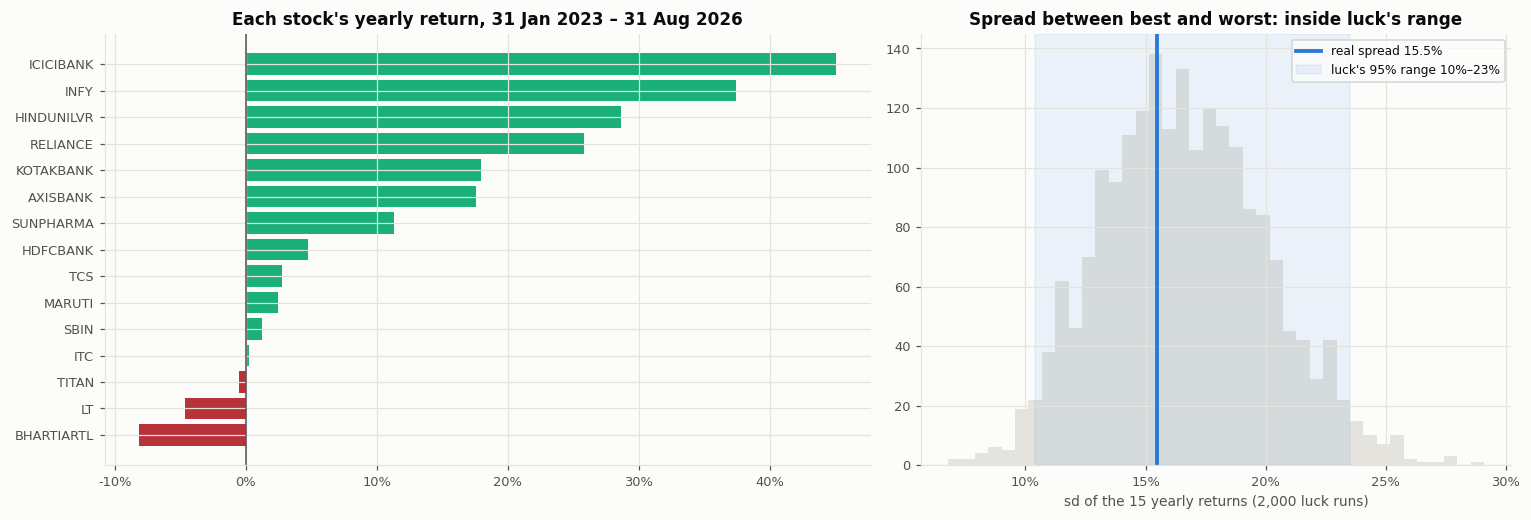

Saved to module_05_equity_markets/outputs/task2
['01_portfolios_vs_luck.png', '02_concentration_risk.png', '03_stock_scorecard.png', 'FINAL_M5_T2_stock_selections.csv', 'key_numbers.json', 'module9_inputs.csv', 'portfolio_returns.csv', 'portfolio_summary.csv', 'september_2026_portfolio.csv', 'stock_scorecard.csv']


,0
Category,Equity investments: ML stock selection (extra ...
What NovaFin would put money into,Picking the top 5 stocks by a model each month...
Return per ₹ deployed (% a year),0.0
Return range (% a year),"Best model (LightGBM) +3.4 points, p = 0.57 (l..."
Bad-year result per ₹ (% a year),-7.42
How the bad year is defined,Worst model's shortfall against holding all 15...
Capacity (₹ crore),—
Evidence strength,Strong negative: no model beats luck (43 test ...
How fast the money can come back,Listed stocks: days
Data gap or assumption,Before trading costs; the stocks in the data l...


In [4]:
%run notebooks/m05_task2_ranking.ipynb

## Final output workbook
Builds **`outputs/FINAL_M5_module_output.xlsx`**: the one file to open for this module's results (project decision P-21).
- Tabs: Read me · Key numbers · Board actions · each task's final file · Hand-off to Module 6 · Decisions · Evidence index.
- Every hand-off figure is computed from the task tabs' rows, and each row says which tab, column(s) and rows it comes from.
- Run after all the tasks above.

In [5]:
%run helpers/m05_final_output.py

Saved: FINAL_M5_module_output.xlsx
                                                                             Figure                                                                                                                                                       Value                                                    Unit
                                              Model whose predictions Module 6 uses                                                                                                                                            Ridge regression                                                       —
                                            Are returns predictable from this data?                                                                                                                                     No: no model beats luck                                                       —
                                                         Ridge's ranking skil